# Phishing URL Detection

This run uses **one real dataset only: PhiUSIIL**. The train, validation and test sets below are partitions of the same PhiUSIIL dataset, not separate datasets.

The CPU-balanced profile caps the training partition at 40,000 URLs, uses at most 2,000 character n-gram features, and trains neural models for 8 epochs. It is a practical first full experiment, not a full-dataset training claim.


## 1. Set the project folder and check the environment

In [1]:
from pathlib import Path
import os, sys, subprocess, shlex, json, shutil
from datetime import datetime

PROJ = Path.home() / 'Downloads' / 'phishing_project'  # change this if your project is elsewhere
os.chdir(PROJ)
assert (PROJ / 'phishing_pipeline_cpu.py').exists(), 'Put phishing_pipeline_cpu.py in the project folder.'
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'

def run(args):
    cmd = [sys.executable, '-u', 'phishing_pipeline_cpu.py'] + shlex.split(args)
    p = subprocess.Popen(cmd, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, bufsize=1)
    for line in p.stdout:
        print(line, end='')
    p.wait()
    if p.returncode != 0:
        raise RuntimeError(f'Command failed with exit code {p.returncode}: {args}')
    print('Completed:', args)

import tensorflow as tf
print('Python:', sys.version)
print('TensorFlow:', tf.__version__)
print('GPU devices:', tf.config.list_physical_devices('GPU') or 'CPU only')


Python: 3.13.5 | packaged by Anaconda, Inc. | (main, Jun 12 2025, 16:37:03) [MSC v.1929 64 bit (AMD64)]
TensorFlow: 2.20.0
GPU devices: CPU only


## 2. Verify the dataset

In [2]:
DATA = PROJ / 'data' / 'PhiUSIIL_Phishing_URL_Dataset.csv'
assert DATA.exists(), f'Dataset not found: {DATA}. Put the original CSV in the data folder.'
import pandas as pd
df = pd.read_csv(DATA, usecols=['URL', 'label'])
print('Rows/columns:', df.shape)
print('Original label counts (PhiUSIIL: 1=legitimate, 0=phishing):')
print(df['label'].value_counts())


Rows/columns: (235795, 2)
Original label counts (PhiUSIIL: 1=legitimate, 0=phishing):
label
1    134850
0    100945
Name: count, dtype: int64


## 3. Create a output folder

In [3]:
OUT = 'results_cpu_final'
if Path(OUT).exists():
    backup = 'results_cpu_backup_' + datetime.now().strftime('%Y%m%d_%H%M%S')
    Path(OUT).rename(backup)
    print(f'Previous output moved to {backup}')
print('New output folder:', OUT)


New output folder: results_cpu_final


## 4. Prepare PhiUSIIL and create its internal partitions

The pipeline creates one cleaned PhiUSIIL file and two split configurations:
- stratified train/validation/test partitions for the main comparison;
- domain-disjoint train/validation/test partitions for a generalisation check.

These are two evaluation protocols over the **same dataset**. They are not D1 and D2.

In [4]:
run(f'prepare --data "{DATA}" --out {OUT}')
stats = json.load(open(f'{OUT}/data_stats.json', encoding='utf-8'))['PhiUSIIL']
print('Duplicates removed:', stats['raw_duplicate_urls_removed'])
print('Final rows:', stats['final_rows'])
print('Class counts:', stats['final_class_counts'])
print('Stratified train rows:', stats['split_tr']['rows'])
print('Validation rows:', stats['split_va']['rows'])
print('Test rows:', stats['split_te']['rows'])
print('Domain overlap in stratified split:', stats['domain_overlap_stratified_split'])
print('Domain overlap in domain-disjoint split:', stats['domain_overlap_domain_split'])



===== prepare =====
{
  "PhiUSIIL": {
    "dataset": "PhiUSIIL",
    "raw_rows": 235795,
    "raw_class_counts": {
      "benign": 134850,
      "phishing": 100945
    },
    "raw_duplicate_urls_removed": 425,
    "conflicting_label_urls_removed": 84,
    "duplicates_after_normalisation_removed": 1764,
    "final_rows": 233522,
    "final_class_counts": {
      "benign": 134808,
      "phishing": 98714
    },
    "split_tr": {
      "rows": 168135,
      "benign": 97061,
      "phishing": 71074
    },
    "split_va": {
      "rows": 18682,
      "benign": 10785,
      "phishing": 7897
    },
    "split_te": {
      "rows": 46705,
      "benign": 26962,
      "phishing": 19743
    },
    "split_dtr": {
      "rows": 170874,
      "benign": 97011,
      "phishing": 73863
    },
    "split_dva": {
      "rows": 18987,
      "benign": 10791,
      "phishing": 8196
    },
    "split_dte": {
      "rows": 43661,
      "benign": 27006,
      "phishing": 16655
    },
    "domain_overlap_strat

## 5. Experiment 1 — classical models across FG1–FG4

Compares Multinomial Naive Bayes, Logistic Regression, Random Forest and XGBoost across all four feature groups. Gaussian Naive Bayes is skipped to keep CPU memory/runtime more manageable. Feature-group ranking is based on **validation accuracy**; test accuracy is retained for final reporting.

In [5]:
run(f'exp1 --out {OUT} --models MNB,LR,RF,XGB --fgs FG1,FG2,FG3,FG4 --skip-gnb --epochs 8 --batch 128 --max-features 2000 --max-train-rows 40000 --fresh')



===== exp1 =====
  MNB   FG1  acc=0.8631  P=0.9343  R=0.7272  F1=0.8179  AUC=0.9087  train=5s
  LR    FG1  acc=0.8940  P=0.9657  R=0.7769  F1=0.8611  AUC=0.9308  train=6s
  RF    FG1  acc=0.8959  P=0.9799  R=0.7694  F1=0.8620  AUC=0.9304  train=64s
  XGB   FG1  acc=0.8998  P=0.9738  R=0.7841  F1=0.8687  AUC=0.9350  train=159s
  MNB   FG2  acc=0.7562  P=0.9504  R=0.4466  F1=0.6077  AUC=0.6586  train=2s
  LR    FG2  acc=0.8267  P=0.9132  R=0.6520  F1=0.7608  AUC=0.8501  train=3s
  RF    FG2  acc=0.8747  P=0.9582  R=0.7357  F1=0.8324  AUC=0.9051  train=11s
  XGB   FG2  acc=0.8799  P=0.9588  R=0.7482  F1=0.8405  AUC=0.9115  train=23s
  MNB   FG3  acc=0.8620  P=0.9342  R=0.7246  F1=0.8161  AUC=0.8955  train=9s
  LR    FG3  acc=0.8955  P=0.9484  R=0.7961  F1=0.8656  AUC=0.9317  train=13s
  RF    FG3  acc=0.9021  P=0.9807  R=0.7839  F1=0.8713  AUC=0.9318  train=55s
  XGB   FG3  acc=0.9032  P=0.9778  R=0.7889  F1=0.8733  AUC=0.9379  train=16s
  MNB   FG4  acc=0.8286  P=1.0000  R=0.5946  F1=0.

## 6. Experiment 3 — deep-learning architecture comparison on FG2

Compares RNN, RCNN, DNN and VDCNN using the same FG2 character-sequence representation. The proposed CNN is evaluated separately in Experiment 4 to avoid duplicating its main evaluation.

In [6]:
run(f'exp3 --out {OUT} --models RNN,RCNN,DNN,VDCNN --epochs 8 --batch 128 --max-features 2000 --max-train-rows 40000 --fresh')



===== exp3 =====
Epoch 1/8
313/313 - 162s - 518ms/step - accuracy: 0.5814 - loss: 0.6913 - val_accuracy: 0.5829 - val_loss: 0.6803
Epoch 2/8
313/313 - 135s - 430ms/step - accuracy: 0.5816 - loss: 0.6780 - val_accuracy: 0.5831 - val_loss: 0.6763
Epoch 3/8
313/313 - 147s - 470ms/step - accuracy: 0.5817 - loss: 0.6771 - val_accuracy: 0.5833 - val_loss: 0.6762
Epoch 4/8
313/313 - 161s - 514ms/step - accuracy: 0.5821 - loss: 0.6767 - val_accuracy: 0.5834 - val_loss: 0.6757
Epoch 5/8
313/313 - 277s - 884ms/step - accuracy: 0.8403 - loss: 0.3854 - val_accuracy: 0.8837 - val_loss: 0.3100
Epoch 6/8
313/313 - 216s - 691ms/step - accuracy: 0.8810 - loss: 0.3146 - val_accuracy: 0.8881 - val_loss: 0.2991
Epoch 7/8
313/313 - 211s - 675ms/step - accuracy: 0.8835 - loss: 0.3058 - val_accuracy: 0.8890 - val_loss: 0.2949
Epoch 8/8
313/313 - 183s - 583ms/step - accuracy: 0.8887 - loss: 0.2979 - val_accuracy: 0.8931 - val_loss: 0.2914

  RNN   FG2  acc=0.8899  P=0.9463  R=0.7842  F1=0.8576  AUC=0.9153  t

## 7. Experiment 4 — proposed character-level CNN on FG2

Evaluates the proposed CNN on the stratified split and the domain-disjoint split of the same PhiUSIIL dataset. The stratified model is saved for the application.

In [7]:
run(f'exp4 --proposed CNN --out {OUT} --epochs 8 --batch 128 --max-features 2000 --max-train-rows 40000')



===== exp4 =====
Epoch 1/8
313/313 - 268s - 858ms/step - accuracy: 0.8642 - loss: 0.3437 - val_accuracy: 0.8966 - val_loss: 0.2830
Epoch 2/8
313/313 - 301s - 963ms/step - accuracy: 0.8951 - loss: 0.2841 - val_accuracy: 0.8975 - val_loss: 0.2751
Epoch 3/8
313/313 - 240s - 766ms/step - accuracy: 0.9007 - loss: 0.2701 - val_accuracy: 0.9013 - val_loss: 0.2668
Epoch 4/8
313/313 - 250s - 799ms/step - accuracy: 0.9060 - loss: 0.2549 - val_accuracy: 0.8960 - val_loss: 0.3053
Epoch 5/8
313/313 - 247s - 789ms/step - accuracy: 0.9124 - loss: 0.2415 - val_accuracy: 0.8839 - val_loss: 0.3482
Epoch 6/8
313/313 - 239s - 765ms/step - accuracy: 0.9141 - loss: 0.2391 - val_accuracy: 0.8530 - val_loss: 0.4118
  CNN   FG2  acc=0.8974  P=0.9678  R=0.7832  F1=0.8658  AUC=0.9294  train=1547s

Epoch 1/8
313/313 - 255s - 815ms/step - accuracy: 0.8654 - loss: 0.3344 - val_accuracy: 0.8895 - val_loss: 0.2957
Epoch 2/8
313/313 - 567s - 2s/step - accuracy: 0.8992 - loss: 0.2750 - val_accuracy: 0.8964 - val_loss:

## 8. Generate tables and inspect accuracy plots


===== tables =====
wrote results_cpu_final\tables.md
Completed: tables --out results_cpu_final
model,fg,accuracy,precision,recall,f1,auc,tn,fp,fn,tp,fpr,tpr,validation_accuracy,validation_precision,validation_recall,validation_f1,train_time_s,fit_time_s,test_time_s,ms_per_url,n_train,n_test,best_params,experiment
MNB,FG1,0.8630767583770474,0.9342790213430505,0.727245099528947,0.8178633476688217,0.9086560556244696,25952,1010,5385,14358,0.037460129070543725,0.727245099528947,0.867091317846055,0.9371770025839793,0.7348360136760795,0.8237632195329689,5.2696356773376465,0.03285384178161621,2.6443183422088623,0.05661745727885371,40000,46705,,exp1
LR,FG1,0.8940370410020341,0.9656887433895744,0.776933596717824,0.8610885002947203,0.9307575173108559,26417,545,4404,15339,0.02021363400341221,0.776933596717824,0.8984584091639011,0.9672897196261683,0.7863745726225149,0.8675001746175874,5.915789604187012,0.6790077686309814,2.6234934329986572,0.05617157548439476,40000,46705,,exp1
RF,FG1,0.89585697462

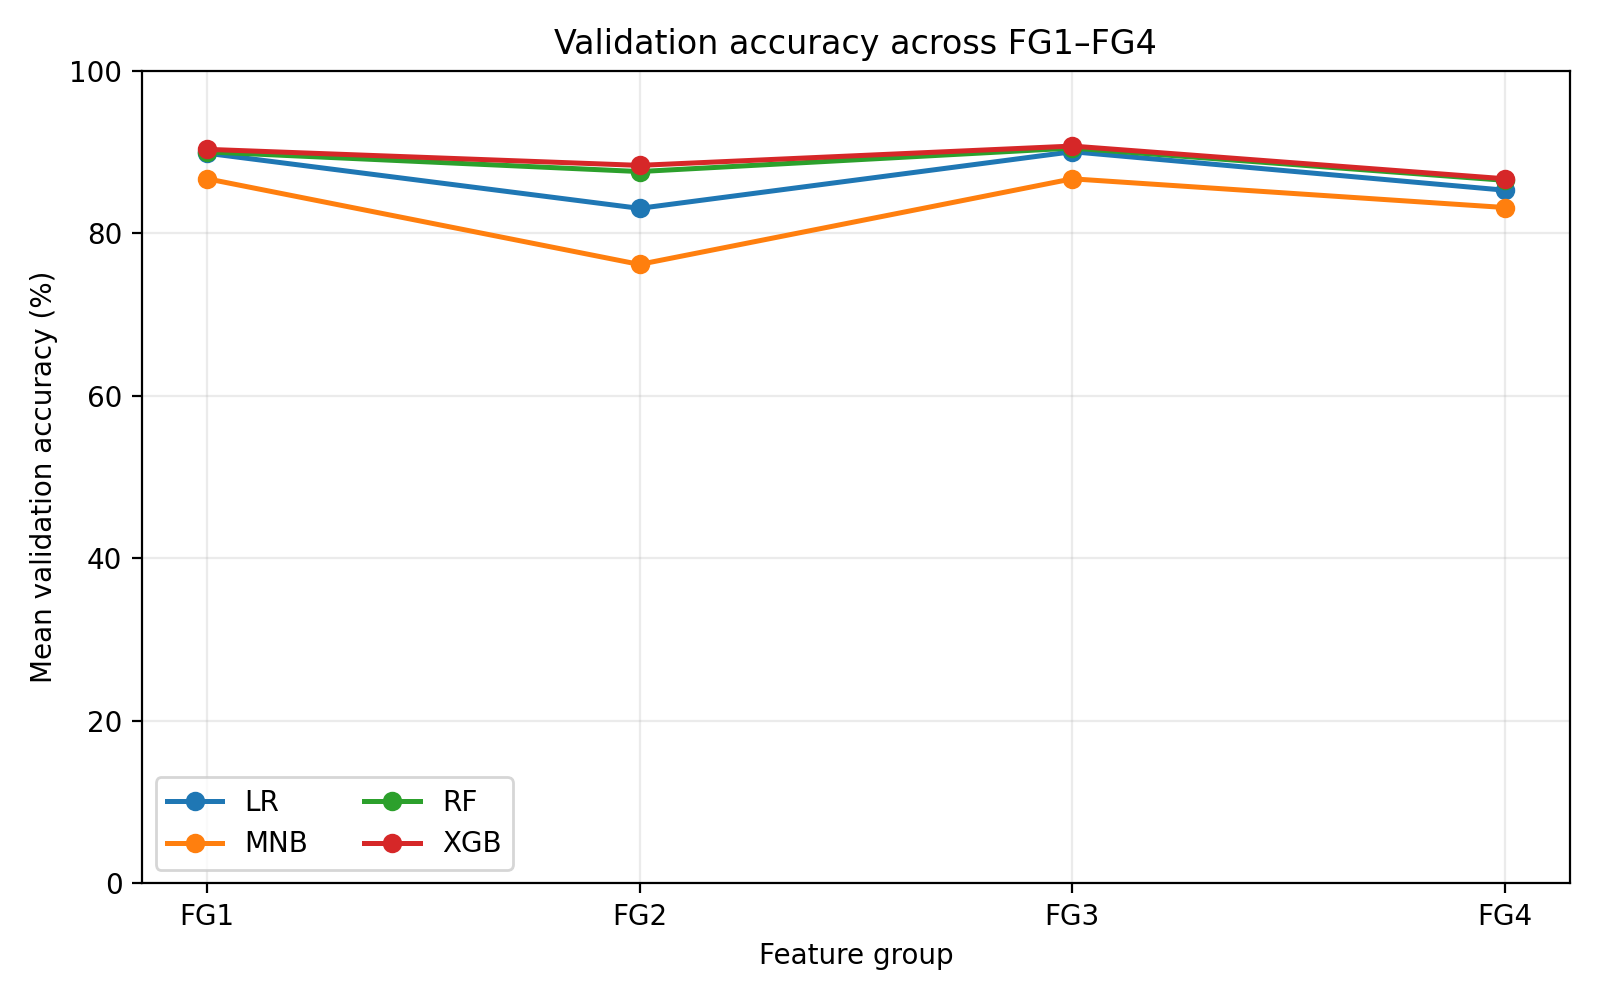

top2_feature_groups_accuracy.png


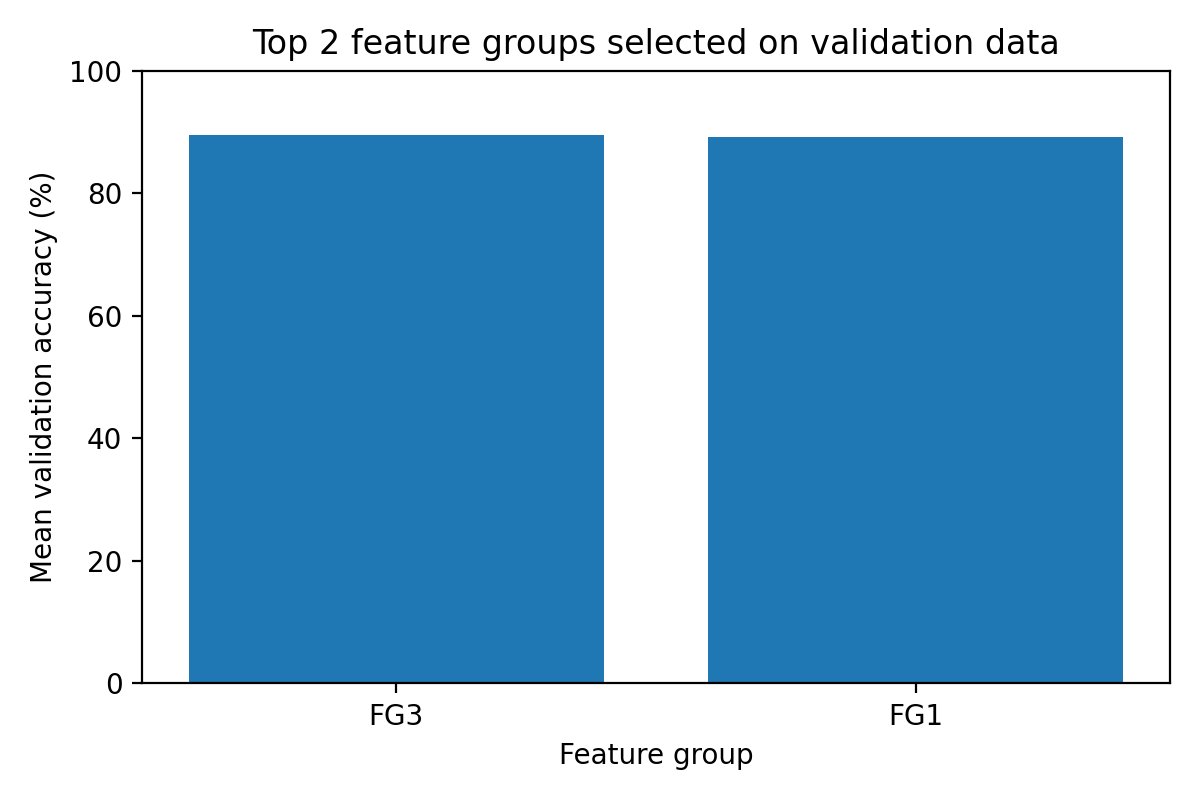

confusion_PhiUSIIL.png


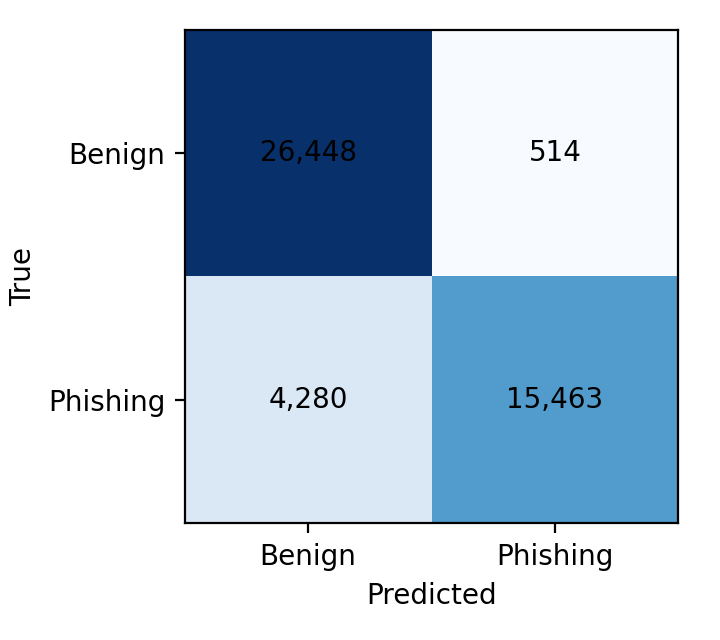

curves_PhiUSIIL.png


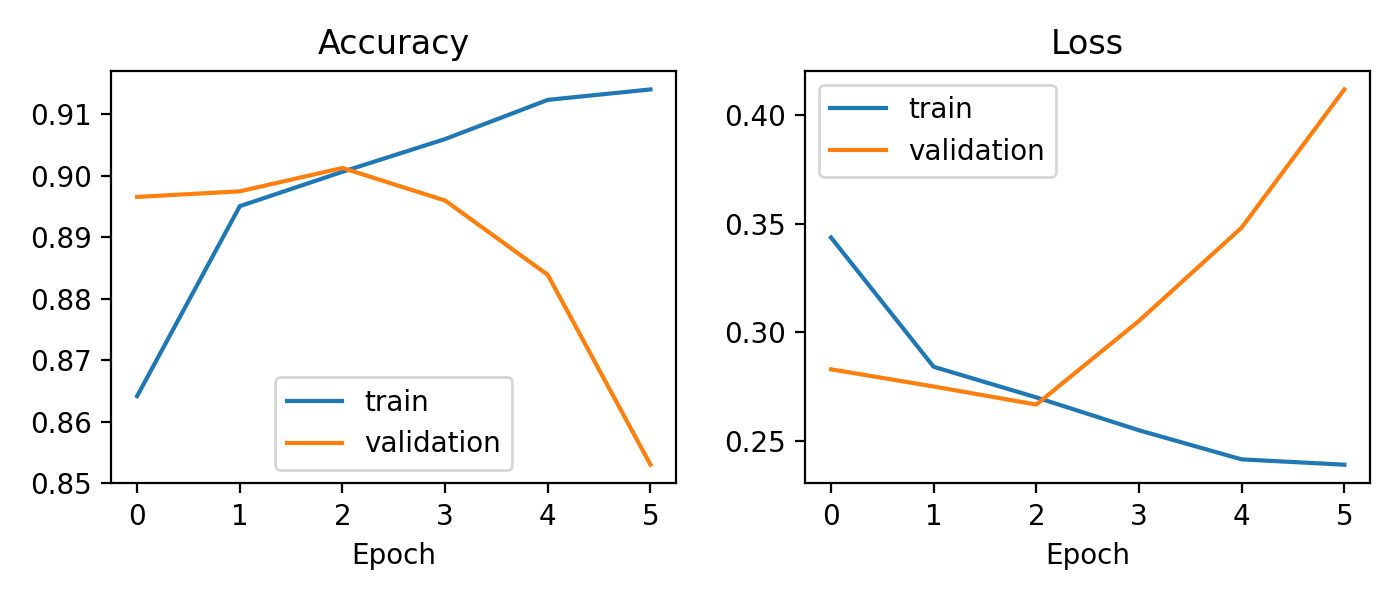

In [8]:
run(f'tables --out {OUT}')
print(open(f'{OUT}/exp1.csv', encoding='utf-8').read()[:7000])
print(open(f'{OUT}/tables.md', encoding='utf-8').read()[:10000])

from IPython.display import Image, display
for fn in ['accuracy_by_feature_group.png', 'top2_feature_groups_accuracy.png',
           'confusion_PhiUSIIL.png', 'curves_PhiUSIIL.png']:
    path = Path(OUT) / fn
    if path.exists():
        print(fn)
        display(Image(filename=str(path)))


## 9. Final outputs

- `clean_PhiUSIIL.csv` and `splits_PhiUSIIL.npz`: one cleaned dataset and its partitions
- `exp1.csv`: classical model comparison across FG1–FG4
- `FG1/` to `FG4/`: per-feature-group result CSV and accuracy chart
- `fg_validation_accuracy_summary.csv`: mean validation accuracy by feature group
- `top2_feature_groups.csv` and `top2_feature_groups_accuracy.png`: top two groups selected using validation accuracy
- `exp3.csv`: deep model comparison on FG2
- `exp4.csv` and `models/`: proposed CNN evaluation and saved model
- `confusion_PhiUSIIL.png` and `curves_PhiUSIIL.png`: final model diagnostics
- `tables.md`: generated research tables

**Important:** test metrics are for final reporting only. Do not select the feature groups or tune the model based on test performance. This balanced run caps the training subset at 40,000 rows; disclose that limit in the methodology. The validation and test partitions are still taken from the complete cleaned PhiUSIIL data.


In [9]:
from pathlib import Path
import shutil
from datetime import datetime

# Project directory
PROJECT_DIR = Path.home() / "Downloads" / "phishing_project"

# Results folder
RESULTS_DIR = PROJECT_DIR / "results_cpu_final"

# ZIP output location
ZIP_DIR = PROJECT_DIR
timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")

ZIP_PATH = ZIP_DIR / f"phishing_results_{timestamp}.zip"

# Check whether results folder exists
if not RESULTS_DIR.exists():
    raise FileNotFoundError(f"Results folder not found: {RESULTS_DIR}")

# Create ZIP
shutil.make_archive(
    str(ZIP_PATH.with_suffix("")),
    "zip",
    root_dir=RESULTS_DIR
)

print("ZIP created successfully!")
print(f"Location: {ZIP_PATH}")
print(f"Size: {ZIP_PATH.stat().st_size / (1024 * 1024):.2f} MB")

ZIP created successfully!
Location: C:\Users\tayal\Downloads\phishing_project\phishing_results_20261123_212501.zip
Size: 85.27 MB
